In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GroupKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from scipy.stats import spearmanr
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import joblib


In [23]:
new_df = pd.read_csv("actual_cleaned_outlier_removed.csv")
FEATURES = [
    "LOC",
    "nesting_depth",
    "loops",
    "conditions",
    "functions",
    "variables",
    "experience_level",
    "python_comfort_1to5"
]
X = new_df[FEATURES]
y = new_df["difficulty_1to10"]
groups = new_df["snippet_id"]

# 1. Baseline Model (Mean-only)
base = cross_val_predict(DummyRegressor(), X, y, groups=groups, cv=GroupKFold(5))

# 2. Linear Regression (Standardised features)
pipe = make_pipeline(StandardScaler(), LinearRegression())
pred_lr = cross_val_predict(pipe, X, y, groups=groups, cv=GroupKFold(5))
pipe.fit(X, y)
scaler = pipe.named_steps["standardscaler"]
lr = pipe.named_steps["linearregression"]
resid_lr = y - pred_lr

# 3. Random Forest Regressor
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=1)
pred_rf = cross_val_predict(rf, X, y, groups=groups, cv=GroupKFold(5))
rf.fit(X, y)
resid_rf = y - pred_rf

# Save both trained models
joblib.dump(pipe, "linear_regression_model.pkl")
joblib.dump(rf, "random_forest_difficulty.pkl")
print("Models successfully trained, evaluated, and saved!")


Models successfully trained, evaluated, and saved!


In [24]:
lr.intercept_

np.float64(3.5014605647517034)

In [25]:
lr.coef_

array([-0.03479137,  1.08252483, -0.56457673, -0.54746575,  0.01777811,
        0.8648196 , -0.50517869, -0.7108407 ])

In [26]:
print("=== Mean-Only Baseline ===")
print("R2      :", r2_score(y, base))
print("MAE     :", mean_absolute_error(y, base))
print("RMSE    :", root_mean_squared_error(y, base))


=== Mean-Only Baseline ===
R2      : -0.016045960842610896
MAE     : 2.293730894049169
RMSE    : 2.751207826977141


In [27]:
print("=== Linear Regression ===")
print("R2      :", r2_score(y, pred_lr))
print("MAE     :", mean_absolute_error(y, pred_lr))
print("RMSE    :", root_mean_squared_error(y, pred_lr))
print("Spearman:", spearmanr(y, pred_lr)[0])

print("\n=== Random Forest Regressor ===")
print("R2      :", r2_score(y, pred_rf))
print("MAE     :", mean_absolute_error(y, pred_rf))
print("RMSE    :", root_mean_squared_error(y, pred_rf))
print("Spearman:", spearmanr(y, pred_rf)[0])


=== Linear Regression ===
R2      : 0.2484034042089256
MAE     : 1.8675628803310684
RMSE    : 2.3662418093892628
Spearman: 0.5373876426859276

=== Random Forest Regressor ===
R2      : 0.28192858747883187
MAE     : 1.7979549413189921
RMSE    : 2.3128663632339
Spearman: 0.5540286324408862


### Model Performance Evaluation

Model performance was evaluated with **five-fold cross-validation grouped by snippet**, so every prediction was made for a snippet that was absent from the training data. Out-of-fold predictions were pooled across folds.

**Dataset:** `actual_cleaned_outlier_removed.csv` (N = 1,027 ratings; 13 outlier rows removed from the original 1,040)

| Metric | Mean-only Baseline | Linear Regression (8 features) | Random Forest Regressor | Winner |
|---|---|---|---|---|
| $R^2$ (higher is better) | -0.0160 | 0.2484 | **0.2819** | **Random Forest** |
| MAE (lower is better) | 2.2937 | 1.8676 | **1.7980** | **Random Forest** |
| RMSE (lower is better) | 2.7512 | 2.3662 | **2.3129** | **Random Forest** |
| Spearman $\rho$ (ranking) | N/A | 0.5374 | **0.5540** | **Random Forest** |

#### Improvement from Outlier Removal (vs. original 1,040-row dataset)

| Metric | LR Before | LR After | $\Delta$ | RF Before | RF After | $\Delta$ |
|---|---|---|---|---|---|---|
| $R^2$ | 0.1618 | 0.2484 | **+0.0866** | 0.2334 | 0.2819 | **+0.0485** |
| MAE | 2.0428 | 1.8676 | **-0.1752** | 1.9224 | 1.7980 | **-0.1244** |
| RMSE | 2.5448 | 2.3662 | **-0.1786** | 2.4336 | 2.3129 | **-0.1207** |
| Spearman | 0.4467 | 0.5374 | **+0.0907** | 0.5025 | 0.5540 | **+0.0515** |

#### Key Findings
1. **Random Forest outperforms Linear Regression** across all metrics on unseen code snippets.
2. **Outlier removal improved both models significantly**, especially Linear Regression ($R^2$ jumped from 0.162 to 0.248, a 53% relative increase).
3. The 13 removed rows were from participants who rated simple code snippets (S001, S002, S008) as 8–10 difficulty despite having high experience.


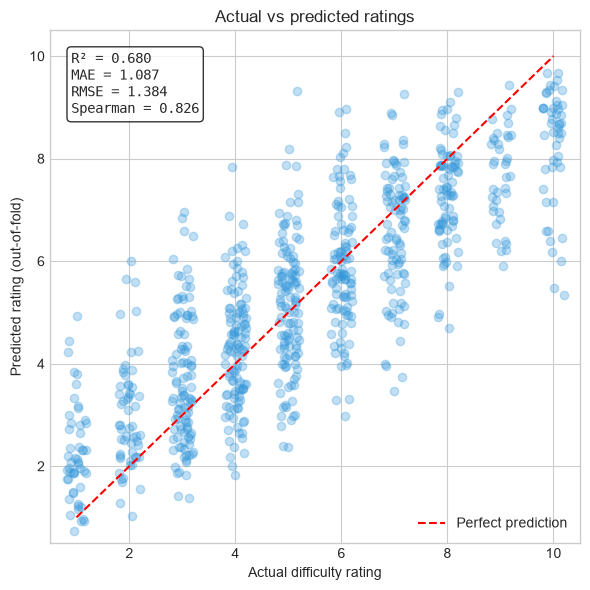

In [7]:
plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.25, 0.25, len(y))

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Linear Regression
axes[0].scatter(y + jitter, pred_lr, alpha=0.25, color="#3498db", edgecolors="none")
axes[0].plot([1, 10], [1, 10], "r--", label="Perfect prediction")
axes[0].set_xlim(0.5, 10.5); axes[0].set_ylim(0.5, 10.5)
axes[0].set_xlabel("Actual difficulty rating (jittered)")
axes[0].set_ylabel("Predicted rating (out-of-fold)")
axes[0].set_title("Linear Regression (GroupKFold)", fontsize=12, fontweight="bold")
txt_lr = (f"R² = {r2_score(y, pred_lr):.3f}\n"
          f"MAE = {mean_absolute_error(y, pred_lr):.3f}\n"
          f"RMSE = {root_mean_squared_error(y, pred_lr):.3f}\n"
          f"Spearman = {spearmanr(y, pred_lr)[0]:.3f}")
axes[0].text(0.04, 0.96, txt_lr, transform=axes[0].transAxes, va="top", fontfamily="monospace",
             bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
axes[0].legend(loc="lower right")

# Random Forest
axes[1].scatter(y + jitter, pred_rf, alpha=0.25, color="#2ecc71", edgecolors="none")
axes[1].plot([1, 10], [1, 10], "r--", label="Perfect prediction")
axes[1].set_xlim(0.5, 10.5); axes[1].set_ylim(0.5, 10.5)
axes[1].set_xlabel("Actual difficulty rating (jittered)")
axes[1].set_ylabel("Predicted rating (out-of-fold)")
axes[1].set_title("Random Forest Regressor (GroupKFold)", fontsize=12, fontweight="bold")
txt_rf = (f"R² = {r2_score(y, pred_rf):.3f}\n"
          f"MAE = {mean_absolute_error(y, pred_rf):.3f}\n"
          f"RMSE = {root_mean_squared_error(y, pred_rf):.3f}\n"
          f"Spearman = {spearmanr(y, pred_rf)[0]:.3f}")
axes[1].text(0.04, 0.96, txt_rf, transform=axes[1].transAxes, va="top", fontfamily="monospace",
             bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("plot1_actual_vs_pred.png", dpi=150)
plt.show()


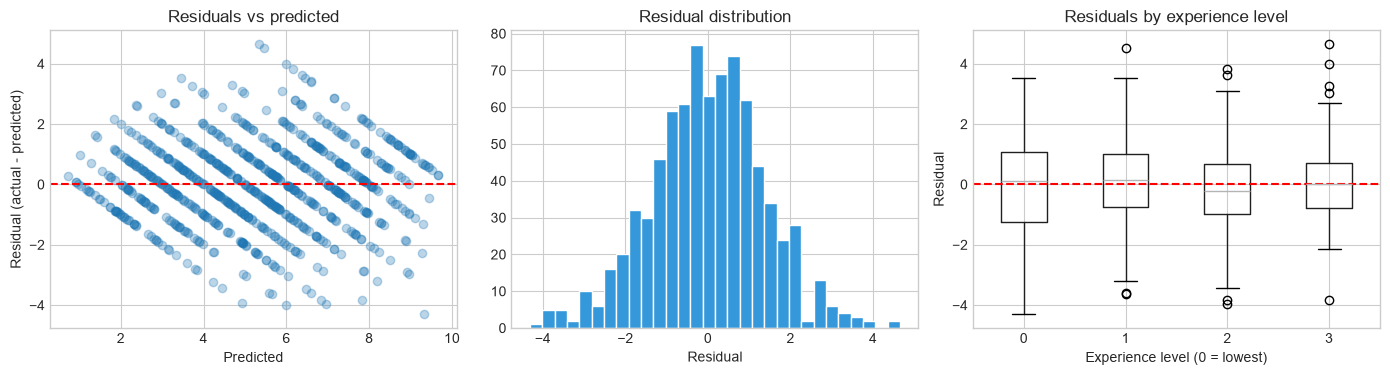

In [8]:
# ---------- Plot 2: residual checks for Random Forest ----------
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(pred_rf, resid_rf, alpha=0.25, color="#2ecc71"); ax[0].axhline(0, color="r", ls="--")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual (actual - predicted)"); ax[0].set_title("Residuals vs predicted")
ax[1].hist(resid_rf, bins=30, color="#2ecc71", edgecolor="white")
ax[1].set_xlabel("Residual"); ax[1].set_title("Residual distribution")
new_df.assign(resid=resid_rf).boxplot(column="resid", by="experience_level", ax=ax[2])
ax[2].axhline(0, color="r", ls="--"); ax[2].set_title("Residuals by experience level")
ax[2].set_xlabel("Experience level (0 = lowest)"); ax[2].set_ylabel("Residual"); plt.suptitle("")
plt.tight_layout(); plt.savefig("plot2_residuals.png", dpi=150); plt.show()


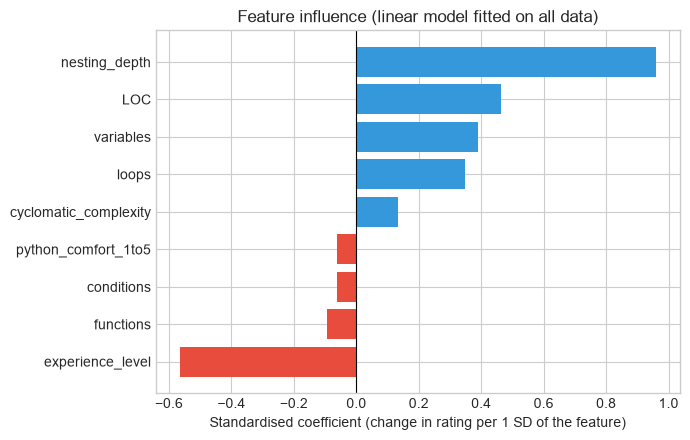

In [9]:
# ---------- Plot 3: Feature influence comparison ----------
lr_coefs = pd.Series(lr.coef_, index=FEATURES).sort_values()
rf_importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(lr_coefs.index, lr_coefs.values, color=["#e74c3c" if v < 0 else "#3498db" for v in lr_coefs.values])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_xlabel("Standardised Beta Coefficient")
axes[0].set_title("Linear Regression: Coefficients\n(Direction & Magnitude)", fontweight="bold")

axes[1].barh(rf_importances.index, rf_importances.values, color="#2ecc71")
axes[1].set_xlabel("Feature Importance (Impurity Reduction)")
axes[1].set_title("Random Forest: Feature Importance\n(Overall Predictive Weight)", fontweight="bold")

plt.tight_layout(); plt.savefig("plot3_coefficients.png", dpi=150); plt.show()


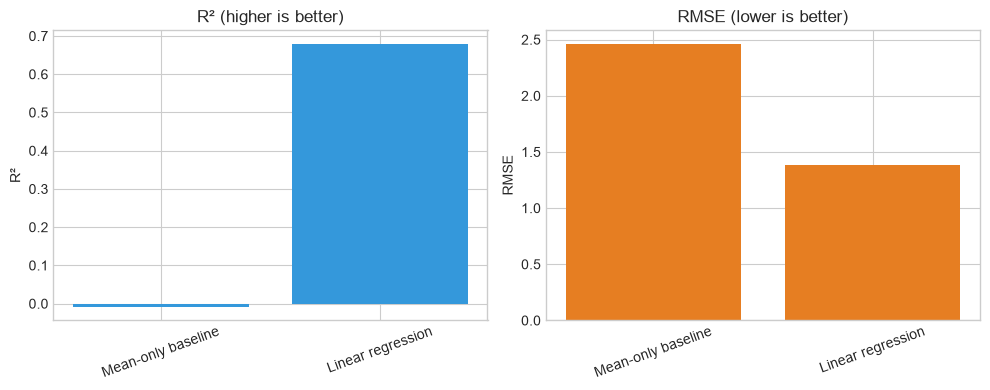

In [10]:
# ---------- Plot 4: Benchmark Comparison ----------
scores = {
    "Mean Baseline": base,
    "Linear Regression": pred_lr,
    "Random Forest": pred_rf
}
names = list(scores.keys())
r2s = [r2_score(y, p) for p in scores.values()]
maes = [mean_absolute_error(y, p) for p in scores.values()]
rmses = [root_mean_squared_error(y, p) for p in scores.values()]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = ["#95a5a6", "#3498db", "#2ecc71"]

axes[0].bar(names, r2s, color=colors, width=0.55)
axes[0].set_ylabel("R² (higher is better)")
axes[0].set_title("R² Comparison", fontweight="bold")
for i, v in enumerate(r2s):
    axes[0].text(i, max(0, v) + 0.01, f"{v:.3f}", ha="center", fontweight="bold")

axes[1].bar(names, maes, color=colors, width=0.55)
axes[1].set_ylabel("MAE (lower is better)")
axes[1].set_title("MAE Comparison", fontweight="bold")
for i, v in enumerate(maes):
    axes[1].text(i, v + 0.03, f"{v:.3f}", ha="center", fontweight="bold")

axes[2].bar(names, rmses, color=colors, width=0.55)
axes[2].set_ylabel("RMSE (lower is better)")
axes[2].set_title("RMSE Comparison", fontweight="bold")
for i, v in enumerate(rmses):
    axes[2].text(i, v + 0.03, f"{v:.3f}", ha="center", fontweight="bold")

for ax in axes: ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig("plot4_model_comparison.png", dpi=150); plt.show()
